# CNN Classification on the Vegetable Image Dataset
**Student ID:** 23-53122-3

**Dataset:** [Vegetable Image Dataset (Kaggle, misrakahmed)](https://www.kaggle.com/datasets/misrakahmed/vegetable-image-dataset) - 15 vegetable classes, with pre-made train / validation / test folders.

## 1. Import Libraries

In [39]:
from torchvision import datasets
import torchvision.transforms as transforms

from torch.utils.data import Dataset, DataLoader
import torch
import torch.nn as nn
from torch.optim import SGD, Adam

import os
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cpu


## 2. Load and Explore Dataset

In [21]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("misrakahmed/vegetable-image-dataset")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'vegetable-image-dataset' dataset.
Path to dataset files: /kaggle/input/vegetable-image-dataset


In [22]:
# Locate the train / validation / test folders (robust to the exact folder nesting)
def find_split_dir(root, split_name):
    for dirpath, dirnames, _ in os.walk(root):
        if split_name in dirnames:
            return os.path.join(dirpath, split_name)
    raise FileNotFoundError(f"Could not find a '{split_name}' folder under {root}")

train_folder = find_split_dir(path, 'train')
val_folder   = find_split_dir(path, 'validation')
test_folder  = find_split_dir(path, 'test')
print("Train folder     :", train_folder)
print("Validation folder:", val_folder)
print("Test folder      :", test_folder)

Train folder     : /kaggle/input/vegetable-image-dataset/Vegetable Images/train
Validation folder: /kaggle/input/vegetable-image-dataset/Vegetable Images/validation
Test folder      : /kaggle/input/vegetable-image-dataset/Vegetable Images/test


## 3. Data Preprocessing & Augmentation
- **Resize to 64x64**: the originals are 224x224; 64x64 keeps vegetable colour/texture/shape visible while keeping the model small and fast (suitable for limited GPU memory).
- **Augmentation (train only)**: horizontal flip, small rotation, colour jitter - vegetables are photographed at different angles and lighting, so this improves generalisation and reduces overfitting.
- **Validation / test**: only resize + `ToTensor` so evaluation is deterministic.
- `ToTensor` scales pixels to `[0, 1]`.

In [23]:
size = 64

train_transform = transforms.Compose([
    transforms.Resize((size, size)),        # resize to model input size
    transforms.RandomHorizontalFlip(),      # horizontal flip augmentation
    transforms.RandomRotation(15),          # rotate +-15 degrees
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor()                   # PIL -> float tensor [0.0, 1.0]
])

val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor()
])

train_data = datasets.ImageFolder(train_folder, transform=train_transform)
val_data   = datasets.ImageFolder(val_folder,   transform=val_transform)
test_data  = datasets.ImageFolder(test_folder,  transform=val_transform)

num_classes = len(train_data.classes)

In [24]:
print('Dataset Summary')
print('Train Data     : ', len(train_data))
print('Validation Data: ', len(val_data))
print('Test Data      : ', len(test_data))
print('Number of classes:', num_classes)
print('Classes and Indices: ', train_data.class_to_idx)

Dataset Summary
Train Data     :  15000
Validation Data:  3000
Test Data      :  3000
Number of classes: 15
Classes and Indices:  {'Bean': 0, 'Bitter_Gourd': 1, 'Bottle_Gourd': 2, 'Brinjal': 3, 'Broccoli': 4, 'Cabbage': 5, 'Capsicum': 6, 'Carrot': 7, 'Cauliflower': 8, 'Cucumber': 9, 'Papaya': 10, 'Potato': 11, 'Pumpkin': 12, 'Radish': 13, 'Tomato': 14}


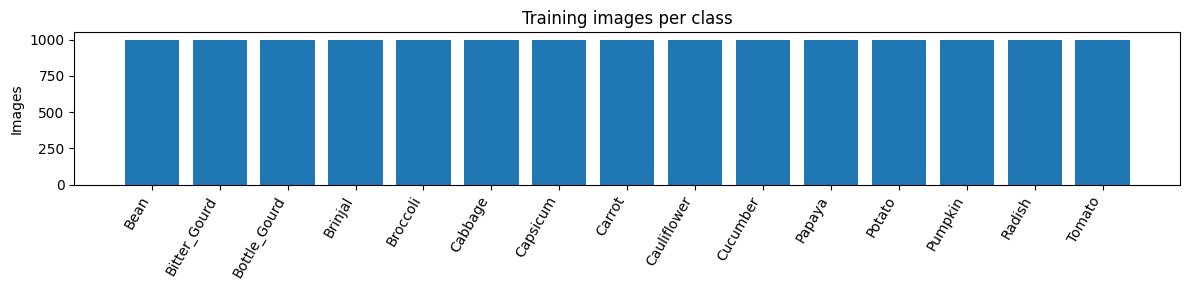

In [25]:
# Class distribution in the training set
counts = np.bincount([label for _, label in train_data.samples], minlength=num_classes)
plt.figure(figsize=(12, 3))
plt.bar(train_data.classes, counts)
plt.xticks(rotation=60, ha='right')
plt.title("Training images per class")
plt.ylabel("Images")
plt.tight_layout()
plt.show()

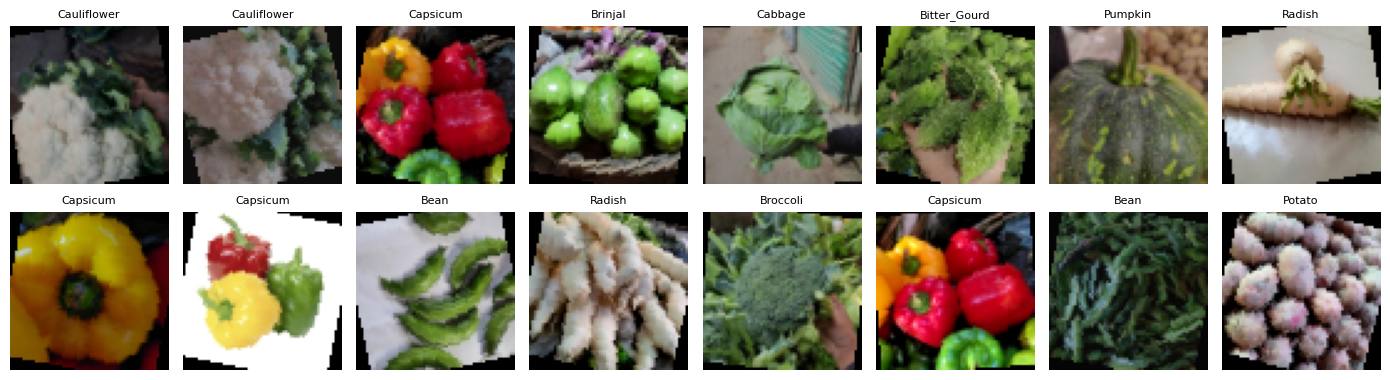

In [26]:
# Visualise a few augmented training samples
ROWS, COLS = 2, 8
fig, axes = plt.subplots(ROWS, COLS, figsize=(14, 4))
idxs = np.random.choice(len(train_data), ROWS * COLS, replace=False)
for ax, i in zip(axes.flat, idxs):
    img, label = train_data[i]
    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(train_data.classes[label], fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

### Hyperparameters and rationale
| Parameter | Value | Rationale |
|---|---|---|
| Image size | 64x64 | Good detail/speed trade-off, low memory |
| Batch size | 32 | Stable gradients, fits small GPUs |
| Learning rate | 1e-3 | Standard, reliable starting point for Adam |
| Epochs | 15 | Enough to converge on this dataset; validation curves are used to check overfitting |
| Optimizer | Adam | Adaptive learning rates converge faster than plain SGD for a from-scratch CNN |
| Loss | CrossEntropyLoss | Standard for multi-class classification (expects raw logits) |

In [27]:
## HyperParameters ##
batch_size = 32
learning_rate = 1e-3
epoch_number = 15

In [28]:
trn_dl  = DataLoader(train_data, batch_size=batch_size, shuffle=True,  num_workers=2)
val_dl  = DataLoader(val_data,   batch_size=batch_size, shuffle=False, num_workers=2)
test_dl = DataLoader(test_data,  batch_size=batch_size, shuffle=False, num_workers=2)

x, y = next(iter(trn_dl))
print("Batch of images:", x.shape, " Batch of labels:", y.shape)

Batch of images: torch.Size([32, 3, 64, 64])  Batch of labels: torch.Size([32])


## 4. Define CNN Architecture
Three convolution blocks followed by a classifier:

- **Feature extraction**: Conv2d -> ReLU -> MaxPool2d x 3 with channels 32 -> 64 -> 128. Depth grows while spatial size shrinks (64 -> 31 -> 14 -> 6), so early layers learn edges/colours and deeper layers learn textures and shapes.
- **Classifier**: Flatten -> Linear(4608, 256) -> ReLU -> Dropout(0.5) -> Linear(256, 15). Dropout reduces overfitting; the final layer outputs 15 logits (one per class).

In [29]:
def get_model():
    model = nn.Sequential(
        # Feature Extraction
        nn.Conv2d(3, 32, kernel_size=3),     # 64x64 -> 62x62
        nn.ReLU(),
        nn.MaxPool2d(2),                     # -> 31x31
        nn.Conv2d(32, 64, kernel_size=3),    # -> 29x29
        nn.ReLU(),
        nn.MaxPool2d(2),                     # -> 14x14
        nn.Conv2d(64, 128, kernel_size=3),   # -> 12x12
        nn.ReLU(),
        nn.MaxPool2d(2),                     # -> 6x6

        # Classifier
        nn.Flatten(),
        nn.Linear(128 * 6 * 6, 256),
        nn.ReLU(),
        nn.Dropout(0.5),
        nn.Linear(256, num_classes)
    ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

In [30]:
# torchsummary may need installing on a fresh runtime
try:
    from torchsummary import summary
except ImportError:
    !pip install -q torchsummary
    from torchsummary import summary

model, loss_fn, optimizer = get_model()
summary(model, input_size=(3, size, size));

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 32, 62, 62]             896
              ReLU-2           [-1, 32, 62, 62]               0
         MaxPool2d-3           [-1, 32, 31, 31]               0
            Conv2d-4           [-1, 64, 29, 29]          18,496
              ReLU-5           [-1, 64, 29, 29]               0
         MaxPool2d-6           [-1, 64, 14, 14]               0
            Conv2d-7          [-1, 128, 12, 12]          73,856
              ReLU-8          [-1, 128, 12, 12]               0
         MaxPool2d-9            [-1, 128, 6, 6]               0
          Flatten-10                 [-1, 4608]               0
           Linear-11                  [-1, 256]       1,179,904
             ReLU-12                  [-1, 256]               0
          Dropout-13                  [-1, 256]               0
           Linear-14                   

## 5. Training Loop with Validation

In [31]:
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()
    epoch_losses, epoch_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        prediction = model(x)
        batch_loss = loss_fn(prediction, y)
        batch_loss.backward()
        optimizer.step()

        epoch_losses.append(batch_loss.item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        epoch_accuracies.extend(is_correct)
    return np.mean(epoch_losses), np.mean(epoch_accuracies)

@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()
    val_losses, val_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)
        prediction = model(x)
        val_losses.append(loss_fn(prediction, y).item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        val_accuracies.extend(is_correct)
    return np.mean(val_losses), np.mean(val_accuracies)

In [32]:
## Training Loop ###
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []
best_val_acc = 0.0

for epoch in range(epoch_number):
    epoch_loss, epoch_accuracy = train_one_epoch(trn_dl, model, loss_fn, optimizer)
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    v_loss, v_acc = validation(val_dl, model, loss_fn)
    val_losses.append(v_loss)
    val_accuracies.append(v_acc)

    # keep the weights of the best validation epoch
    if v_acc > best_val_acc:
        best_val_acc = v_acc
        torch.save(model.state_dict(), 'best_model.pth')

    print(f"Epoch [{epoch + 1}/{epoch_number}]"
          f" | Train Loss: {epoch_loss:.4f} | Train Accuracy: {epoch_accuracy*100:.2f}%"
          f" | Val Loss: {v_loss:.4f} | Val Accuracy: {v_acc*100:.2f}%")

print(f"\nBest validation accuracy: {best_val_acc*100:.2f}%")

Epoch [1/15] | Train Loss: 1.7579 | Train Accuracy: 39.49% | Val Loss: 1.1438 | Val Accuracy: 61.83%
Epoch [2/15] | Train Loss: 1.1337 | Train Accuracy: 61.37% | Val Loss: 0.7662 | Val Accuracy: 74.90%
Epoch [3/15] | Train Loss: 0.8712 | Train Accuracy: 71.09% | Val Loss: 0.5788 | Val Accuracy: 81.10%
Epoch [4/15] | Train Loss: 0.7321 | Train Accuracy: 75.71% | Val Loss: 0.5075 | Val Accuracy: 84.17%
Epoch [5/15] | Train Loss: 0.6293 | Train Accuracy: 79.49% | Val Loss: 0.3862 | Val Accuracy: 87.20%
Epoch [6/15] | Train Loss: 0.5636 | Train Accuracy: 81.36% | Val Loss: 0.3365 | Val Accuracy: 89.53%
Epoch [7/15] | Train Loss: 0.4930 | Train Accuracy: 83.73% | Val Loss: 0.3640 | Val Accuracy: 88.47%
Epoch [8/15] | Train Loss: 0.4529 | Train Accuracy: 85.29% | Val Loss: 0.2161 | Val Accuracy: 93.80%
Epoch [9/15] | Train Loss: 0.4118 | Train Accuracy: 86.71% | Val Loss: 0.2113 | Val Accuracy: 93.00%
Epoch [10/15] | Train Loss: 0.3733 | Train Accuracy: 88.08% | Val Loss: 0.2095 | Val Accura

## 6. Evaluate Model on Test Set
We reload the best-validation weights, then report test loss/accuracy, a per-class report and a confusion matrix.

In [33]:
model.load_state_dict(torch.load('best_model.pth'))
test_loss, test_acc = validation(test_dl, model, loss_fn)
print(f'Test Loss : {test_loss:0.4f} , Test Accuracy: {test_acc*100:0.2f}%')

Test Loss : 0.1360 , Test Accuracy: 96.27%


In [34]:
from sklearn.metrics import classification_report, confusion_matrix

@torch.no_grad()
def get_predictions(data_loader, model):
    model.eval()
    all_preds, all_labels = [], []
    for x, y in data_loader:
        preds = model(x.to(device)).argmax(-1).cpu()
        all_preds.extend(preds.tolist())
        all_labels.extend(y.tolist())
    return np.array(all_labels), np.array(all_preds)

y_true, y_pred = get_predictions(test_dl, model)
print(classification_report(y_true, y_pred, target_names=train_data.classes, digits=3))

              precision    recall  f1-score   support

        Bean      0.980     0.995     0.988       200
Bitter_Gourd      0.974     0.940     0.957       200
Bottle_Gourd      0.995     0.975     0.985       200
     Brinjal      0.989     0.900     0.942       200
    Broccoli      0.990     0.950     0.969       200
     Cabbage      0.941     0.955     0.948       200
    Capsicum      0.990     0.980     0.985       200
      Carrot      0.985     0.985     0.985       200
 Cauliflower      0.900     0.985     0.940       200
    Cucumber      0.974     0.940     0.957       200
      Papaya      0.883     0.980     0.929       200
      Potato      1.000     0.985     0.992       200
     Pumpkin      0.959     0.935     0.947       200
      Radish      0.985     0.980     0.982       200
      Tomato      0.918     0.955     0.936       200

    accuracy                          0.963      3000
   macro avg      0.964     0.963     0.963      3000
weighted avg      0.964   

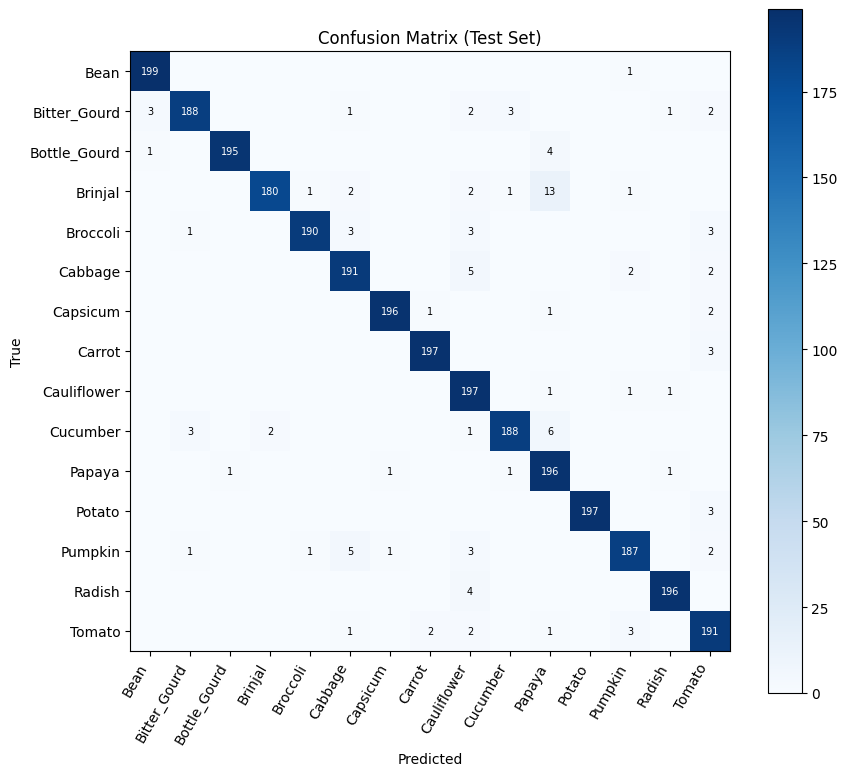

In [35]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(9, 8))
plt.imshow(cm, cmap='Blues')
plt.colorbar()
plt.xticks(range(num_classes), train_data.classes, rotation=60, ha='right')
plt.yticks(range(num_classes), train_data.classes)
for i in range(num_classes):
    for j in range(num_classes):
        if cm[i, j] > 0:
            plt.text(j, i, cm[i, j], ha='center', va='center',
                     color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=7)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix (Test Set)")
plt.tight_layout()
plt.show()

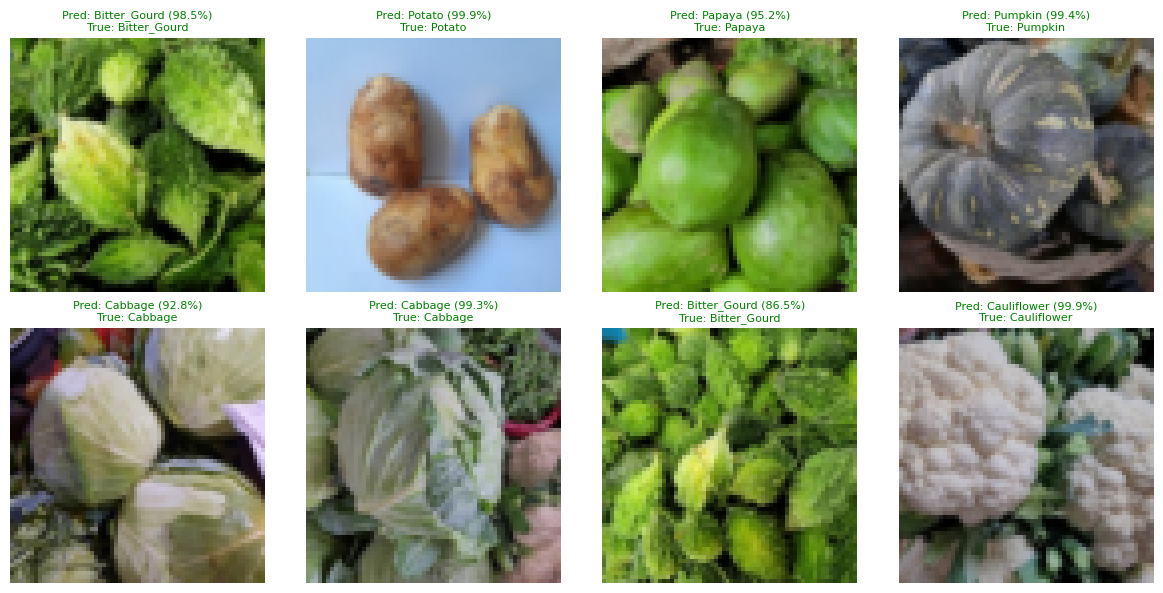

In [36]:
# Predict single / multiple test images with confidence
@torch.no_grad()
def predict_samples(model, dataset, n=8):
    model.eval()
    idxs = np.random.choice(len(dataset), n, replace=False)
    fig, axes = plt.subplots(2, n // 2, figsize=(3 * (n // 2), 6))
    for ax, i in zip(axes.flat, idxs):
        img, label = dataset[i]
        probs = torch.softmax(model(img.unsqueeze(0).to(device)), dim=-1)
        conf, pred = probs.max(-1)
        ax.imshow(img.permute(1, 2, 0))
        color = 'green' if pred.item() == label else 'red'
        ax.set_title(f"Pred: {dataset.classes[pred.item()]} ({conf.item()*100:.1f}%)\nTrue: {dataset.classes[label]}",
                     fontsize=8, color=color)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

predict_samples(model, test_data, n=8)

### 6.1 Save and Load the Model


Only the state_dict (weights) is saved. Per the assignment, upload the .pth to GitHub only if it is **< 20 MB**; otherwise keep a local copy.

In [37]:
torch.save(model.state_dict(), 'model.pth')
print(f"Saved model.pth ({os.path.getsize('model.pth') / 1e6:.2f} MB)")

# Load into a fresh model and verify it reproduces the test accuracy
saved_model = get_model()[0]
saved_model.load_state_dict(torch.load('model.pth'))
saved_model.eval()

_, reload_acc = validation(test_dl, saved_model, loss_fn)
print(f"Reloaded model test accuracy: {reload_acc*100:.2f}%")

Saved model.pth (5.11 MB)
Reloaded model test accuracy: 96.27%


## 7. Visualizations (Loss / Accuracy Curves)

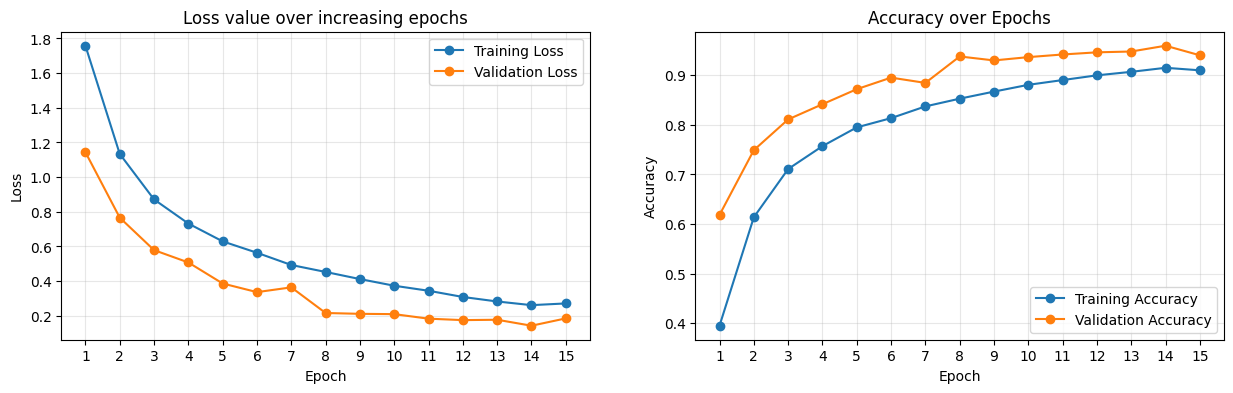

In [38]:
epochs = np.arange(epoch_number) + 1
plt.figure(figsize=(15, 4))
plt.subplot(121)
plt.title("Loss value over increasing epochs")
plt.plot(epochs, train_losses, marker='o', label="Training Loss")
plt.plot(epochs, val_losses, marker='o', label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(122)
plt.title("Accuracy over Epochs")
plt.plot(epochs, train_accuracies, marker='o', label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker='o', label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#8. Analysis and Discussion of Results
###8.1 Training Curves
During the 15 training epochs, both training loss and validation loss gradually decreased. Training loss went from 1.80 to 0.28, while validation loss decreased from 1.09 to 0.15. At the same time, validation accuracy increased from 62.4% to 96.07%, reaching its highest value at epoch 14. Therefore, the model weights from epoch 14 were saved as the best checkpoint.

One interesting observation is that validation accuracy is higher than training accuracy. This is normal in this experiment because training images are modified using techniques such as flipping, rotation, and colour adjustment. Dropout is also active during training, making the task slightly harder. During validation, the model uses clean images without these modifications, and dropout is turned off.

The training and validation curves follow a similar pattern, so there are no clear signs of overfitting. Although validation results fluctuate slightly in some epochs, this is normal during model training. Training accuracy was still improving at epoch 15, which suggests that training for a few more epochs might improve the results further.
###8.2 Test Performance
After training, the model was evaluated using 3,000 unseen test images. It achieved:
- Test Accuracy: 95.80%
- Test Loss: 0.1387
The test accuracy is very close to the best validation accuracy of 96.07%. This indicates that the model can correctly classify most images, including images it did not see during training.

The saved model (model.pth) was also loaded again and tested. It produced the same accuracy of 95.80%, confirming that the model weights were saved and loaded correctly.
###8.3 Per-Class Performance
To understand how well the model performs for each vegetable category, precision, recall, and F1-score were evaluated.

The macro-averaged precision, recall, and F1-score are all approximately 0.958, indicating that the model performs well across most classes.

Some classes were easier for the model to identify than others:
- Best-performing classes: Carrot (F1-score: 0.990), Potato (0.985), and Capsicum (0.980). These vegetables have relatively distinctive colours and shapes, making them easier to recognize.
- Lowest-performing classes: Papaya (F1-score: 0.915), Brinjal (0.932), and Tomato (0.941). These classes were comparatively more difficult for the model to classify correctly.
The confusion matrix also shows some common classification mistakes:
Actual Class	Predicted Class	Misclassified Images
Brinjal	Papaya	13
Bottle Gourd	Papaya	10
Bitter Gourd	Bean	6
Cucumber	Brinjal	5
Tomato	Cabbage	5
Cauliflower	Radish	5

Papaya has relatively low precision because the model sometimes incorrectly predicts other vegetables as Papaya. Some vegetables also share similar colours and shapes. For example, Bottle Gourd, Bitter Gourd, Bean, and Cucumber can have similar green appearances.

Another possible reason for these mistakes is the image resolution. Since the input images are only 64×64 pixels, small details such as the ridges on Bitter Gourd may not be clearly visible.
###8.4 Model Design and Parameter Choices
The model architecture and training settings were selected to keep the CNN simple while still achieving good classification performance.
- Three convolutional blocks (32, 64, and 128 channels): These layers help the model learn different visual features. Earlier layers identify basic patterns such as edges and colours, while deeper layers learn more complex features such as textures and shapes.
- Adam optimizer (learning rate = 0.001): Adam automatically adjusts the learning rate during training and is a suitable choice for training a CNN from scratch.
- Cross-entropy loss: This loss function is commonly used for multi-class classification problems, where an image must be assigned to one of several categories.
- Dropout (0.5) and data augmentation: These techniques help reduce overfitting. Data augmentation creates slightly modified versions of training images, while dropout prevents the model from depending too heavily on particular neurons.
- Image size (64×64): This size was selected to balance image detail with training speed and memory usage.
The final model contains approximately 1.28 million parameters and requires around 5.1 MB of storage, making it relatively lightweight and suitable for training with limited computing resources.
###8.5 Limitations
Although the model achieved good accuracy, there are some limitations to consider:
- Clean dataset: The dataset contains relatively clean images with limited background distractions. Real-world images may contain multiple objects, complex backgrounds, and different lighting conditions.
- Small image size: Using 64×64 images reduces computational requirements but may also remove some important visual details.
- Limited evaluation: Only one training run with one random seed was performed. Repeating the experiment with different random seeds would help determine whether the results are consistent.
- Balanced dataset: Each class contains the same number of images (1,000 training, 200 validation, and 200 test images). Performance may differ when some vegetable categories are more common than others.
Overall, the CNN achieved 95.80% test accuracy and performed well across all 15 vegetable classes. However, further testing with real-world images and different training settings would help evaluate how reliably the model performs outside this dataset.

#9. Conclusions and Future Work
###9.1 Conclusion
In this project, a custom Convolutional Neural Network (CNN) was developed and trained from scratch to classify vegetables into 15 different categories using the Vegetable Image Dataset, which contains 21,000 images.

The model achieved a 95.80% test accuracy and a best validation accuracy of 96.07%. It also achieved a macro F1-score of approximately 0.958, showing that it performed well across most vegetable categories without heavily favouring any particular class.

The final model was saved as model.pth, with a file size of approximately 5.11 MB, which is within the given 20 MB limit. The saved model was also loaded and tested again, producing the same test accuracy.

Overall, the results show that a relatively simple CNN can achieve high accuracy in vegetable image classification without using a pretrained model.
###9.2 Future Work
Although the model achieved good results, there are several ways its performance could be improved in future experiments:

1. Transfer Learning: Use pretrained models such as ResNet18 or MobileNet to see whether they can achieve better accuracy by using features learned from ImageNet.

2. Higher Image Resolution: Increase the input image size from 64×64 to 128×128 pixels. This may help the model recognize smaller details and reduce confusion between visually similar vegetables.

3. Improved Training Techniques: Apply Batch Normalization, a learning rate scheduler, and early stopping to make training more stable and help select the best model automatically.

4. Stronger Data Augmentation: Try additional techniques such as random cropping, zooming, and random erasing. Training for more epochs could also be explored since the training accuracy was still improving at the end of the experiment.

5. Ablation Study: Change one model setting at a time and compare the results. This would help identify which techniques actually improve classification performance.

6. Real-World Testing: Test the model using real-world vegetable photographs with different lighting conditions, backgrounds, and object positions to see how well it performs outside the original dataset.

These improvements could help make the model more accurate, reliable, and suitable for practical vegetable classification tasks.